CONTINGENCY TABLE
             Passed  Failed
Coaching         40      10
No Coaching      20      30

Row and column totals:
Coaching       50
No Coaching    50
dtype: int64
Passed    60
Failed    40
dtype: int64

P(Passed) = 0.60
P(Passed and Coaching) = 0.40
P(Passed | Coaching) = 0.80


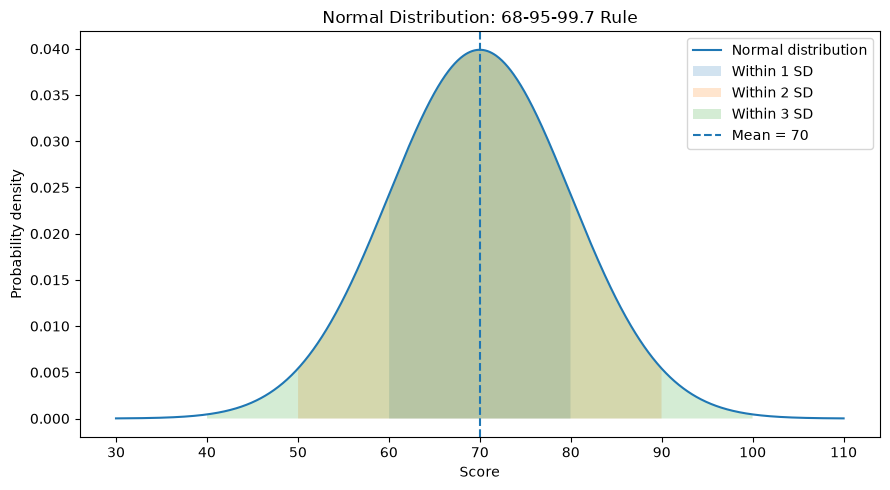


BINOMIAL SIMULATION
Expected successes: 5.0
Simulated average: 4.9857


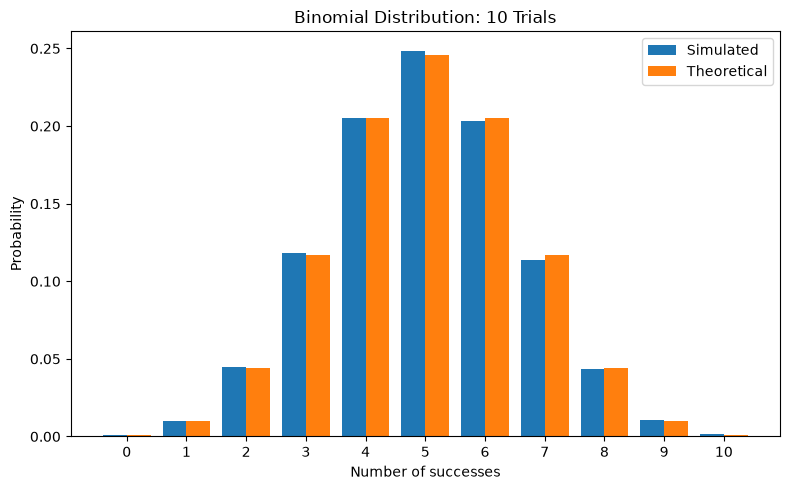


CENTRAL LIMIT THEOREM
Population mean: 1.0051048522333277
Mean of sample means (n=5): 0.9954019339307669
Mean of sample means (n=30): 0.996212133926065
SD of sample means (n=5): 0.4437353301438368
SD of sample means (n=30): 0.18256113137566676


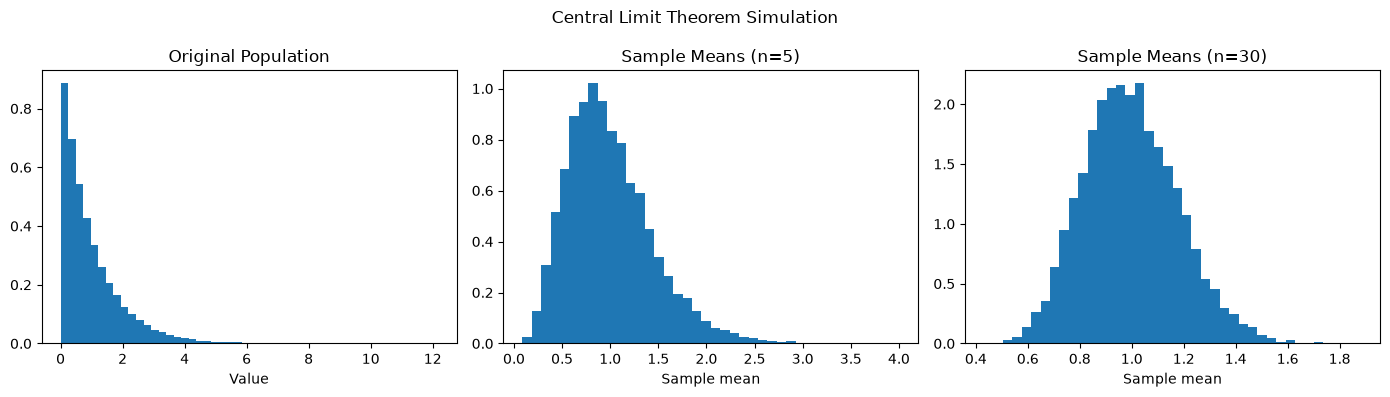


All probability and sampling analyses completed!


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# ------------------------------------------------
# 1. PROBABILITY USING A CONTINGENCY TABLE
# ------------------------------------------------
table = pd.DataFrame(
    [[40, 10], [20, 30]],
    index=["Coaching", "No Coaching"],
    columns=["Passed", "Failed"]
)

print("CONTINGENCY TABLE")
print(table)
print("\nRow and column totals:")
print(table.sum(axis=1))
print(table.sum(axis=0))

total = table.to_numpy().sum()

p_A = table.loc[:, "Passed"].sum() / total
p_A_and_B = table.loc["Coaching", "Passed"] / total
p_A_given_B = (
    table.loc["Coaching", "Passed"]
    / table.loc["Coaching"].sum()
)

print(f"\nP(Passed) = {p_A:.2f}")
print(f"P(Passed and Coaching) = {p_A_and_B:.2f}")
print(f"P(Passed | Coaching) = {p_A_given_B:.2f}")

# ------------------------------------------------
# 2. NORMAL DISTRIBUTION: 68-95-99.7 RULE
# ------------------------------------------------
mu = 70
sigma = 10

x = np.linspace(mu - 4*sigma, mu + 4*sigma, 1000)
y = (
    1 / (sigma * np.sqrt(2 * np.pi))
    * np.exp(-0.5 * ((x - mu) / sigma)**2)
)

plt.figure(figsize=(9, 5))
plt.plot(x, y, label="Normal distribution")

for k in [1, 2, 3]:
    mask = (x >= mu - k*sigma) & (x <= mu + k*sigma)
    plt.fill_between(x[mask], y[mask], alpha=0.2,
                     label=f"Within {k} SD")

plt.axvline(mu, linestyle="--", label="Mean = 70")
plt.title("Normal Distribution: 68-95-99.7 Rule")
plt.xlabel("Score")
plt.ylabel("Probability density")
plt.legend()
plt.tight_layout()
plt.savefig("normal_distribution.png")
plt.show()

# ------------------------------------------------
# 3. BINOMIAL DISTRIBUTION SIMULATION
# ------------------------------------------------
n = 10
p = 0.5
simulations = 10000

results = rng.binomial(n=n, p=p, size=simulations)
counts = np.bincount(results, minlength=n + 1)
observed_prob = counts / simulations

# Theoretical binomial probabilities
from math import comb

theoretical_prob = np.array([
    comb(n, k) * p**k * (1-p)**(n-k)
    for k in range(n + 1)
])

print("\nBINOMIAL SIMULATION")
print("Expected successes:", n * p)
print("Simulated average:", results.mean())

plt.figure(figsize=(8, 5))
plt.bar(np.arange(n + 1) - 0.2, observed_prob,
        width=0.4, label="Simulated")
plt.bar(np.arange(n + 1) + 0.2, theoretical_prob,
        width=0.4, label="Theoretical")
plt.title("Binomial Distribution: 10 Trials")
plt.xlabel("Number of successes")
plt.ylabel("Probability")
plt.xticks(range(n + 1))
plt.legend()
plt.tight_layout()
plt.savefig("binomial_distribution.png")
plt.show()

# ------------------------------------------------
# 4. CENTRAL LIMIT THEOREM SIMULATION
# ------------------------------------------------
# Original population is right-skewed
population = rng.exponential(scale=1, size=100000)

# Repeated random samples from the population
number_of_samples = 10000
means_n5 = rng.exponential(
    scale=1, size=(number_of_samples, 5)
).mean(axis=1)

means_n30 = rng.exponential(
    scale=1, size=(number_of_samples, 30)
).mean(axis=1)

print("\nCENTRAL LIMIT THEOREM")
print("Population mean:", population.mean())
print("Mean of sample means (n=5):", means_n5.mean())
print("Mean of sample means (n=30):", means_n30.mean())
print("SD of sample means (n=5):", means_n5.std())
print("SD of sample means (n=30):", means_n30.std())

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].hist(population, bins=50, density=True)
axes[0].set_title("Original Population")
axes[0].set_xlabel("Value")

axes[1].hist(means_n5, bins=40, density=True)
axes[1].set_title("Sample Means (n=5)")
axes[1].set_xlabel("Sample mean")

axes[2].hist(means_n30, bins=40, density=True)
axes[2].set_title("Sample Means (n=30)")
axes[2].set_xlabel("Sample mean")

fig.suptitle("Central Limit Theorem Simulation")
plt.tight_layout()
plt.savefig("central_limit_theorem.png")
plt.show()

print("\nAll probability and sampling analyses completed!")
